# Session 8 · Advanced Unsupervised Learning: Dimensionality Reduction

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-08-dimensionality-reduction.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: PCA from scratch with NumPy

In [1]:
"""PCA from scratch: standardise, covariance, eigen-decomposition, projection; compare with scikit-learn."""
import numpy as np
from sklearn.decomposition import PCA

rng = np.random.default_rng(0)
# 200 students: maths, physics and computing marks are correlated; art is independent
ability = rng.normal(0, 1, 200)
X = np.c_[70 + 10 * ability + rng.normal(0, 4, 200),
          68 + 9 * ability + rng.normal(0, 4, 200),
          72 + 8 * ability + rng.normal(0, 5, 200),
          65 + rng.normal(0, 10, 200)]
cols = ["maths", "physics", "computing", "art"]

Xs = (X - X.mean(0)) / X.std(0)                      # 1. standardise
C = np.cov(Xs, rowvar=False)                          # 2. covariance matrix (4 x 4)
eigval, eigvec = np.linalg.eigh(C)                    # 3. eigen-decomposition (ascending)
order = eigval.argsort()[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]      # 4. sort largest first
ratio = eigval / eigval.sum()
print("explained variance ratio:", ratio.round(3))
print("cumulative:              ", ratio.cumsum().round(3))
print("\nloadings (columns = PC1, PC2):")
for name, row in zip(cols, eigvec[:, :2]):
    print(f"  {name:<10}{row[0]:7.2f}{row[1]:7.2f}")
Z = Xs @ eigvec[:, :2]                                # 5. project onto 2 components
print("\nfirst 3 students in PC space:\n", Z[:3].round(2))

sk = PCA(2).fit(Xs)
print("\nscikit-learn ratio:", sk.explained_variance_ratio_.round(3), "(same values; signs of PCs may flip)")

explained variance ratio: [0.652 0.249 0.062 0.037]
cumulative:               [0.652 0.901 0.963 1.   ]

loadings (columns = PC1, PC2):
  maths       -0.59  -0.00
  physics     -0.58  -0.03
  computing   -0.56  -0.06
  art         -0.06   1.00

first 3 students in PC space:
 [[ 0.42 -0.65]
 [ 0.57  0.93]
 [-0.25  0.09]]

scikit-learn ratio: [0.652 0.249] (same values; signs of PCs may flip)


### Example 2 · Intermediate: scree plot, choosing k and reconstruction

50% of variance needs  5 of 64 components
80% of variance needs 13 of 64 components
90% of variance needs 21 of 64 components
95% of variance needs 29 of 64 components
99% of variance needs 41 of 64 components
k= 2: mean squared reconstruction error =  13.42
k=10: mean squared reconstruction error =   4.91
k=40: mean squared reconstruction error =   0.22


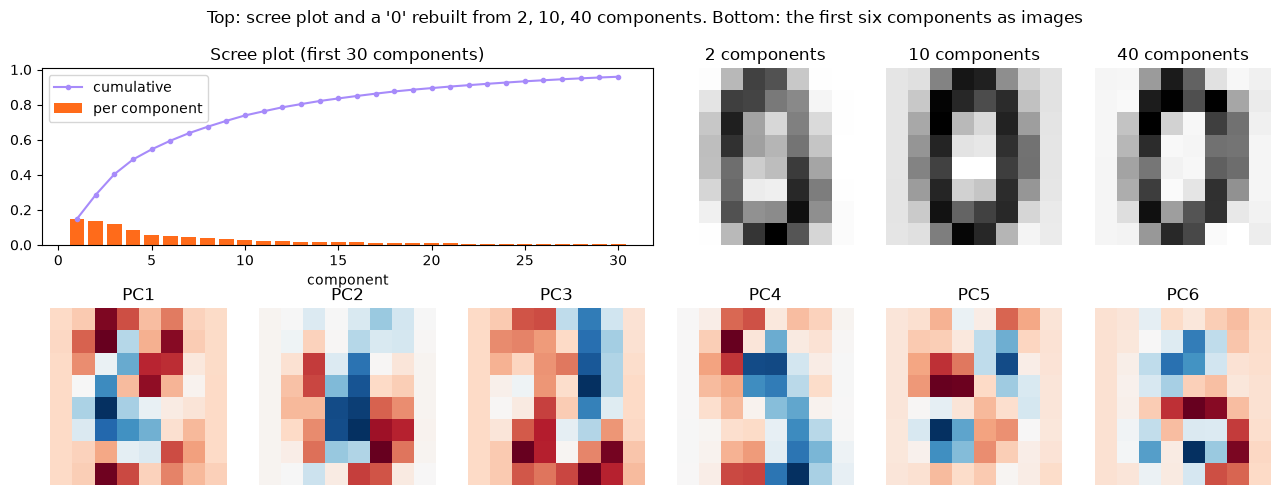

In [2]:
"""PCA on 8x8 digit images: scree plot, components for 95% variance, and image reconstruction quality."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

X, y = load_digits(return_X_y=True)
pca = PCA().fit(X)
cum = pca.explained_variance_ratio_.cumsum()
for thr in [.5, .8, .9, .95, .99]:
    print(f"{thr:.0%} of variance needs {np.argmax(cum >= thr) + 1:>2} of 64 components")

fig, ax = plt.subplots(2, 6, figsize=(13, 5))
ax0 = plt.subplot2grid((2, 6), (0, 0), colspan=3)
ax0.bar(range(1, 31), pca.explained_variance_ratio_[:30], color="#FF6B1A", label="per component")
ax0.plot(range(1, 31), cum[:30], color="#A78BFA", marker="o", ms=3, label="cumulative")
ax0.set_title("Scree plot (first 30 components)"); ax0.set_xlabel("component"); ax0.legend()
for a in ax[0, :3].ravel(): a.remove()
for j, k in enumerate([2, 10, 40]):
    p = PCA(k).fit(X)
    rec = p.inverse_transform(p.transform(X[:1]))
    err = np.mean((X - p.inverse_transform(p.transform(X))) ** 2)
    print(f"k={k:>2}: mean squared reconstruction error = {err:6.2f}")
    ax[0, 3 + j].imshow(rec.reshape(8, 8), cmap="gray_r"); ax[0, 3 + j].set_title(f"{k} components"); ax[0, 3 + j].axis("off")
for j in range(6):
    ax[1, j].imshow(pca.components_[j].reshape(8, 8), cmap="RdBu"); ax[1, j].set_title(f"PC{j + 1}"); ax[1, j].axis("off")
fig.suptitle("Top: scree plot and a '0' rebuilt from 2, 10, 40 components. Bottom: the first six components as images")
fig.tight_layout(); fig.savefig("session-08_pca_digits.png", dpi=100); plt.show()

### Example 3 · Intermediate: PCA inside a model pipeline

In [3]:
"""PCA as preprocessing: accuracy and training time vs number of components; tune n_components with CV."""
import time
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

X, y = load_digits(return_X_y=True)
print("components  CV accuracy  time (s)")
for k in [5, 10, 20, 30, 64]:
    pipe = make_pipeline(StandardScaler(), PCA(k, random_state=0), LogisticRegression(max_iter=3000))
    t0 = time.perf_counter(); acc = cross_val_score(pipe, X, y, cv=5).mean(); dt = time.perf_counter() - t0
    print(f"{k:>10}  {acc:>11.3f}  {dt:>8.2f}")

pipe = Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=0)), ("svm", SVC())])
gs = GridSearchCV(pipe, {"pca__n_components": [10, 20, 30, 0.95], "svm__C": [1, 10]}, cv=5).fit(X, y)
print(f"\nbest: {gs.best_params_}  CV accuracy {gs.best_score_:.3f}")
print("note: n_components=0.95 means 'keep enough components for 95% of variance' ->",
      gs.best_estimator_.named_steps["pca"].n_components_ if gs.best_params_["pca__n_components"] == 0.95 else "not chosen")

components  CV accuracy  time (s)


         5        0.771      0.25


        10        0.840      0.36


        20        0.899      0.63


        30        0.907      0.46


        64        0.920      1.99



best: {'pca__n_components': 0.95, 'svm__C': 10}  CV accuracy 0.949
note: n_components=0.95 means 'keep enough components for 95% of variance' -> 40


### Example 4 · Advanced: PCA vs t-SNE on the same data

PCA    trustworthiness@10 = 0.830   5-NN accuracy on the 2-D map = 0.603
t-SNE  trustworthiness@10 = 0.993   5-NN accuracy on the 2-D map = 0.977


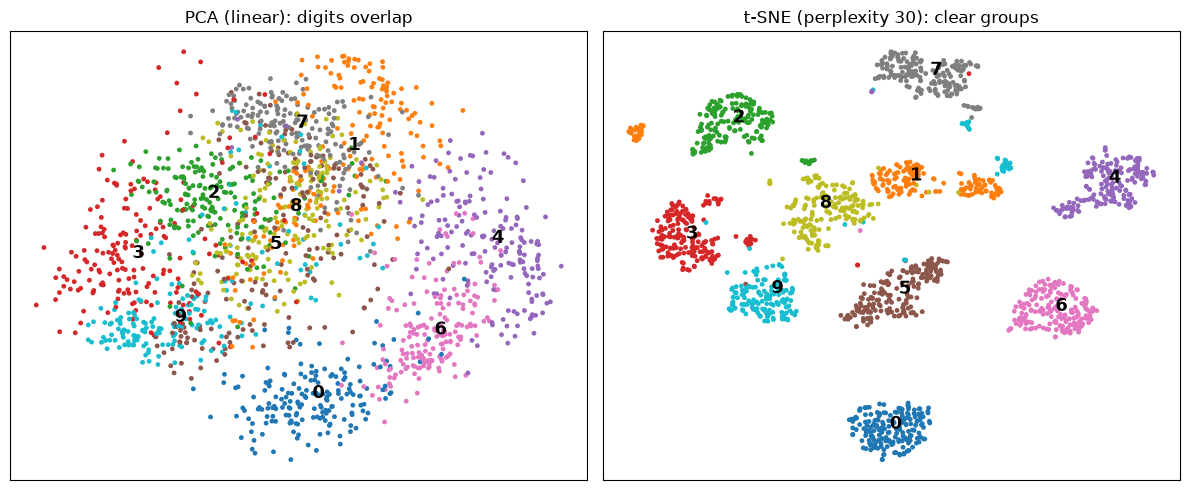

In [4]:
"""Compare a 2-D PCA projection with a t-SNE embedding of the digits and measure neighbourhood preservation."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

X, y = load_digits(return_X_y=True)
Z_pca = PCA(2, random_state=0).fit_transform(X)
X50 = PCA(30, random_state=0).fit_transform(X)                 # speed-up trick: PCA first
Z_tsne = TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=0).fit_transform(X50)

for name, Z in [("PCA", Z_pca), ("t-SNE", Z_tsne)]:
    tw = trustworthiness(X, Z, n_neighbors=10)
    knn = cross_val_score(KNeighborsClassifier(5), Z, y, cv=5).mean()
    print(f"{name:<6} trustworthiness@10 = {tw:.3f}   5-NN accuracy on the 2-D map = {knn:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, Z, t in [(ax[0], Z_pca, "PCA (linear): digits overlap"), (ax[1], Z_tsne, "t-SNE (perplexity 30): clear groups")]:
    sc = a.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=6)
    for d in range(10):
        cx, cy = np.median(Z[y == d], axis=0); a.text(cx, cy, str(d), fontsize=13, weight="bold")
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); fig.savefig("session-08_pca_vs_tsne.png", dpi=100); plt.show()

### Example 5 · Advanced: the effect of perplexity (and seeds)

true spread (mean distance to own centre): [0.93, 6.13, 3.11]


perplexity   2: spread on the map (tight, wide, mid) = [12.8, 32.8, 22.7]


perplexity  10: spread on the map (tight, wide, mid) = [4.9, 12.7, 8.2]


perplexity  30: spread on the map (tight, wide, mid) = [1.6, 4.7, 2.8]


perplexity 100: spread on the map (tight, wide, mid) = [0.0, 1.2, 0.4]


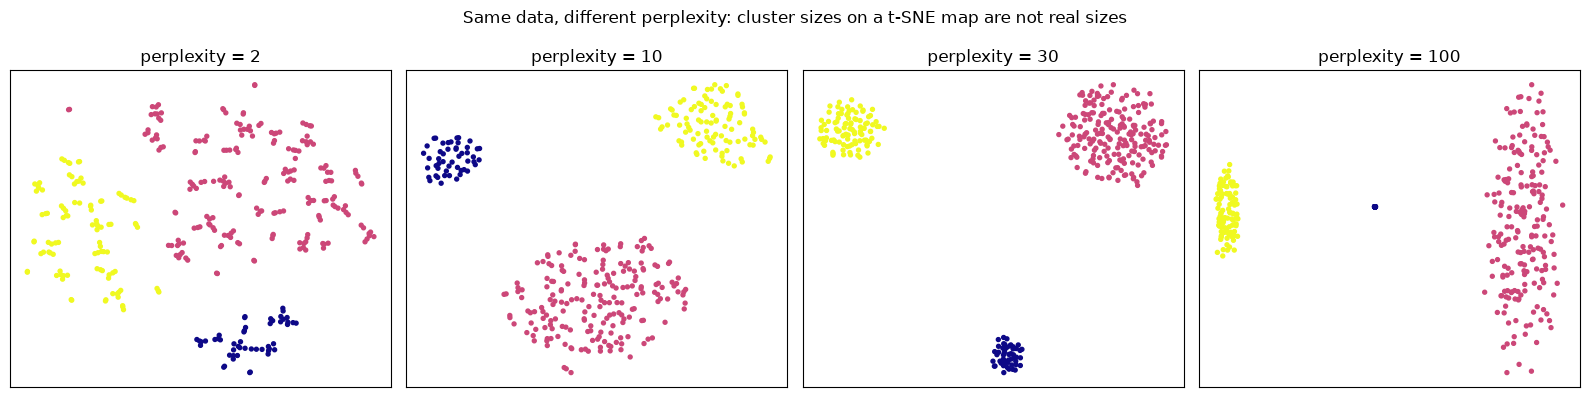


two random seeds give different coordinates: [-32.7   0.3] vs [-4.2 29.9] (the grouping is the same, the layout is not)


In [5]:
"""t-SNE with perplexity 2, 10, 30 and 100 on three clusters of very different sizes and spreads."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

rng = np.random.default_rng(0)
# 10-D data: one tight cluster (50), one wide cluster (200), and one mid cluster (100)
A = rng.normal(0, .3, (50, 10)); B = rng.normal(5, 2.0, (200, 10)); C = rng.normal(-5, 1.0, (100, 10))
X = np.vstack([A, B, C]); y = np.repeat([0, 1, 2], [50, 200, 100])
print("true spread (mean distance to own centre):",
      [round(float(np.linalg.norm(g - g.mean(0), axis=1).mean()), 2) for g in (A, B, C)])

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, perp in zip(ax, [2, 10, 30, 100]):
    Z = TSNE(2, perplexity=perp, init="pca", learning_rate="auto", random_state=1).fit_transform(X)
    spread = [round(float(np.linalg.norm(Z[y == k] - Z[y == k].mean(0), axis=1).mean()), 1) for k in range(3)]
    print(f"perplexity {perp:>3}: spread on the map (tight, wide, mid) = {spread}")
    a.scatter(Z[:, 0], Z[:, 1], c=y, cmap="plasma", s=8); a.set_title(f"perplexity = {perp}"); a.set_xticks([]); a.set_yticks([])
fig.suptitle("Same data, different perplexity: cluster sizes on a t-SNE map are not real sizes")
fig.tight_layout(); fig.savefig("session-08_perplexity.png", dpi=100); plt.show()

Z1 = TSNE(2, perplexity=30, random_state=1, init="random").fit_transform(X)
Z2 = TSNE(2, perplexity=30, random_state=7, init="random").fit_transform(X)
print("\ntwo random seeds give different coordinates:", Z1[0].round(1), "vs", Z2[0].round(1),
      "(the grouping is the same, the layout is not)")

### 🏙️ Real-life data problem: understanding a 30-question customer survey

survey shape: (1500, 30)
explained variance of first 6 PCs: [0.266 0.186 0.076 0.072 0.02  0.02 ]
components with eigenvalue > 1 (Kaiser rule): 4, together 60.0%

average loading of each question theme on each component:
           PC1   PC2   PC3   PC4
branch   0.24  0.01  0.26 -0.05
digital -0.22  0.17  0.21  0.07
fees     0.04  0.26 -0.09 -0.25
staff    0.15  0.20 -0.09  0.27

mean component score per segment:
           PC1   PC2   PC3   PC4
segment                        
0       -1.29 -3.39 -0.03  0.05
1       -1.99  1.51  0.07 -0.03
2        3.34  0.25 -0.07  0.00


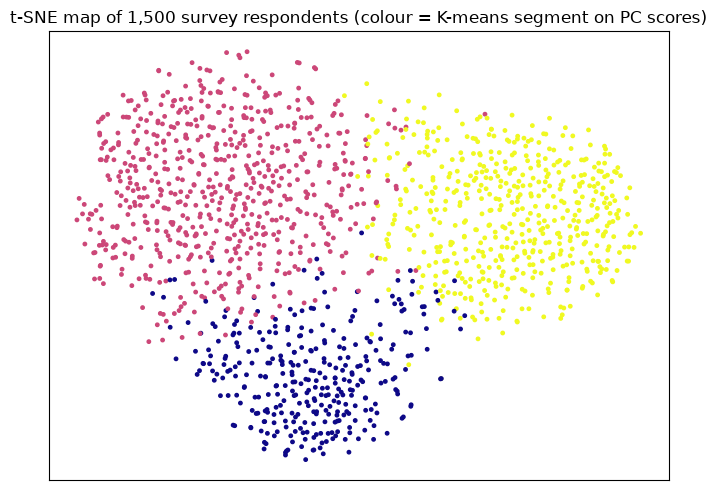

In [6]:
"""Real-life problem: reduce a 30-question survey to a few attitude scores with PCA, then map with t-SNE."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

rng = np.random.default_rng(5)
n = 1500
themes = {"digital": 8, "branch": 8, "fees": 7, "staff": 7}             # questions per hidden attitude
groups = rng.choice(3, n, p=[.45, .35, .20])                            # young digital, traditional, unhappy
means = {0: {"digital": 1.0, "branch": -0.6, "fees": 0.2, "staff": 0.1},
         1: {"digital": -0.8, "branch": 0.9, "fees": 0.1, "staff": 0.8},
         2: {"digital": -0.3, "branch": -0.5, "fees": -1.2, "staff": -0.9}}
cols, data = [], []
for theme, q in themes.items():
    latent = np.array([means[g][theme] for g in groups]) + rng.normal(0, .6, n)
    for i in range(q):
        ans = np.clip(np.round(3 + 0.9 * latent + rng.normal(0, .7, n)), 1, 5)
        data.append(ans); cols.append(f"{theme}_q{i + 1}")
survey = pd.DataFrame(np.array(data).T, columns=cols)
print("survey shape:", survey.shape)

Xs = StandardScaler().fit_transform(survey)
pca = PCA().fit(Xs)
print("explained variance of first 6 PCs:", pca.explained_variance_ratio_[:6].round(3))
k = int((pca.explained_variance_ > 1).sum())                           # Kaiser rule: eigenvalue > 1
print(f"components with eigenvalue > 1 (Kaiser rule): {k}, together {pca.explained_variance_ratio_[:k].sum():.1%}")

pca_k = PCA(k, random_state=0).fit(Xs)
load = pd.DataFrame(pca_k.components_.T, index=cols, columns=[f"PC{i + 1}" for i in range(k)])
theme_load = load.groupby(lambda c: c.split("_")[0]).mean().round(2)
print("\naverage loading of each question theme on each component:\n", theme_load.to_string())

scores = pd.DataFrame(pca_k.transform(Xs), columns=load.columns)
scores["segment"] = KMeans(3, n_init=10, random_state=0).fit_predict(scores)
print("\nmean component score per segment:\n", scores.groupby("segment").mean().round(2).to_string())

Z = TSNE(2, perplexity=40, init="pca", learning_rate="auto", random_state=0).fit_transform(Xs)
plt.figure(figsize=(6.5, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=scores["segment"], cmap="plasma", s=6)
plt.title("t-SNE map of 1,500 survey respondents (colour = K-means segment on PC scores)")
plt.xticks([]); plt.yticks([]); plt.tight_layout(); plt.savefig("session-08_survey_map.png", dpi=110); plt.show()

### 🧩 Mini project: compressing and visualising a product catalogue

40 attributes -> 5 components keep 92.0% of variance
storage: 24,000 numbers -> 3,000 numbers (12%)
customers who viewed phone-000 may like: ['phone-044', 'phone-073', 'phone-040']
customers who viewed laptop-010 may like: ['laptop-078', 'laptop-025', 'laptop-061']
customers who viewed smartwatch-020 may like: ['smartwatch-093', 'smartwatch-129', 'smartwatch-032']


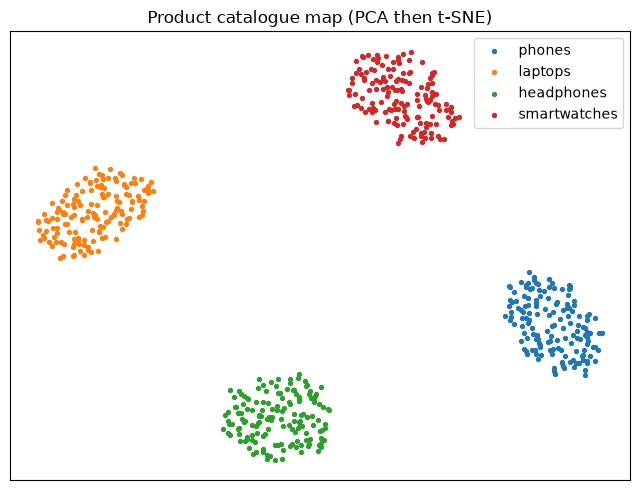

In [7]:
"""Mini project: compress a 40-feature product catalogue with PCA, find similar products, map it with t-SNE."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(8)
categories = ["phones", "laptops", "headphones", "smartwatches"]
singular = ["phone", "laptop", "headphone", "smartwatch"]
n_per = 150
centres = rng.normal(0, 3, (4, 6))                       # 6 hidden product properties per category
latent = np.vstack([c + rng.normal(0, 1, (n_per, 6)) for c in centres])
mixing = rng.normal(0, 1, (6, 40))                       # 40 measured attributes mix the hidden ones
X = latent @ mixing + rng.normal(0, 1.5, (len(latent), 40))
cat = np.repeat(categories, n_per)
names = [f"{c}-{i:03d}" for c in singular for i in range(n_per)]

Xs = StandardScaler().fit_transform(X)
pca = PCA(0.90, random_state=0).fit(Xs)
Z = pca.transform(Xs)
print(f"40 attributes -> {pca.n_components_} components keep {pca.explained_variance_ratio_.sum():.1%} of variance")
print(f"storage: {X.size:,} numbers -> {Z.size:,} numbers ({Z.size / X.size:.0%})")

nn = NearestNeighbors(n_neighbors=4).fit(Z)
for q in [0, 160, 470]:
    idx = nn.kneighbors(Z[q:q + 1], return_distance=False)[0][1:]
    print(f"customers who viewed {names[q]} may like: {[names[i] for i in idx]}")

emb = TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=0).fit_transform(Z)
plt.figure(figsize=(6.5, 5))
for c in categories:
    m = cat == c; plt.scatter(emb[m, 0], emb[m, 1], s=8, label=c)
plt.legend(); plt.xticks([]); plt.yticks([]); plt.title("Product catalogue map (PCA then t-SNE)")
plt.tight_layout(); plt.savefig("session-08_mini_project_catalogue.png", dpi=110); plt.show()